In [1]:
!pip install -q vaderSentiment
from google.colab import drive
drive.mount('/content/drive')

import re, json, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

DATA = Path('/content/drive/MyDrive/NLP_AT2')
OUT = DATA / 'outputs_nb'          # everything this notebook saves goes here
OUT.mkdir(exist_ok=True)
# Roles fixed before any test city was processed: tune on Philadelphia only.
CITIES = {'philadelphia': 'development', 'new_orleans': 'test', 'tampa': 'test'}
SEED = 42
vader = SentimentIntensityAnalyzer()
print('Files in Drive folder:', sorted(p.name for p in DATA.iterdir()))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 832.8 kB/s eta 0:00:00
Mounted at /content/drive
Files in Drive folder: ['archive (2).zip', 'brewview_code.zip', 'new_orleans_cafes.parquet', 'outputs', 'outputs_nb', 'philadelphia_cafes.parquet', 'tampa_cafes.parquet']


In [2]:
# Each aspect is a list of regex patterns, matched case-insensitively on word
# boundaries. 'noise' and 'study' are our additions for the core use case
# ("a quiet cafe to study"); the other 12 follow the Austin dataset's labels.
ASPECTS = {
    "coffee": [r"coffee", r"espresso", r"latte", r"lattes", r"cappuccino", r"cortado",
               r"americano", r"macchiato", r"mocha", r"cold brew", r"drip", r"pour[- ]?over",
               r"flat white", r"brew", r"beans?", r"roast(?:ed|s|er|ery)?", r"barista"],
    "tea": [r"tea", r"teas", r"chai", r"matcha", r"kombucha", r"herbal"],
    "food": [r"food", r"pastr(?:y|ies)", r"croissants?", r"muffins?", r"bagels?",
             r"sandwich(?:es)?", r"breakfast", r"brunch", r"lunch", r"tacos?", r"cakes?",
             r"cookies?", r"donuts?", r"doughnuts?", r"scones?", r"kolaches?", r"toast",
             r"waffles?", r"snacks?", r"menu"],
    "vibe": [r"vibe", r"vibes", r"atmosphere", r"ambien(?:ce|t)", r"ambiance", r"decor",
             r"aesthetic", r"cozy", r"cosy", r"charming", r"hip", r"interior", r"music",
             r"feel(?:s)? like", r"homey"],
    "service": [r"service", r"staff", r"baristas", r"employees?", r"friendly", r"rude",
                r"unfriendly", r"welcoming", r"customer service", r"cashier", r"owner",
                r"server", r"helpful"],
    "seating": [r"seat(?:s|ing)?", r"chairs?", r"tables?", r"couch(?:es)?", r"sofas?",
                r"booths?", r"patio", r"outdoor", r"spacious", r"cramped", r"comfy", r"comfortable"],
    "price": [r"price[sd]?", r"pricey", r"pricy", r"expensive", r"cheap", r"overpriced",
              r"afford(?:able)?", r"value", r"cost(?:s|ly)?", r"worth", r"\$\d+"],
    "parking": [r"parking", r"parked", r"parking lot", r"garage"],
    "location": [r"location", r"located", r"neighbou?rhood", r"downtown", r"close to",
                 r"nearby", r"convenient(?:ly)?", r"walking distance"],
    "hours": [r"hours", r"open(?:s)? (?:late|early)", r"close[sd]? (?:early|late)",
              r"24 hours", r"late night", r"opening", r"closing time"],
    "internet": [r"wi-?fi", r"internet", r"wireless", r"connection", r"password"],
    "alcohol": [r"beers?", r"wines?", r"cocktails?", r"alcohol", r"booze", r"mimosas?", r"happy hour"],
    "study": [r"stud(?:y|ying|ied)", r"homework", r"laptops?", r"work(?:ing)? (?:from|on|remotely)",
              r"get (?:some )?work done", r"outlets?", r"plugs?", r"remote work",
              r"productive", r"read(?:ing)? a book", r"exam"],
    "noise": [r"quiet", r"calm", r"peaceful", r"loud", r"noisy", r"noise", r"crowded",
              r"packed", r"busy", r"chill", r"relaxed", r"relaxing", r"blaring", r"hectic",
              r"tranquil", r"serene"],
}
# Noise is scored by direction (+1 quiet, -1 loud) rather than VADER, because
# VADER treats words like "quiet" and "busy" as neutral.
QUIET_CUES = [r"quiet", r"calm", r"peaceful", r"chill", r"relaxed", r"relaxing",
              r"tranquil", r"serene", r"low[- ]key"]
LOUD_CUES = [r"loud", r"noisy", r"noise", r"crowded", r"packed", r"busy", r"blaring",
             r"hectic", r"chaotic"]
print(f"{len(ASPECTS)} aspects, {sum(len(v) for v in ASPECTS.values())} patterns")

14 aspects, 152 patterns


In [3]:
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\s+\+\s+|\s*\n+\s*")
# Split on contrast words so "Wifi is mediocre, but I love the ambiance"
# does not give wifi a positive score.
CLAUSE_SPLIT = re.compile(r",?\s+(?:but|however|although|though|yet)\s+", re.I)
ASPECT_RE = {a: re.compile(r"\b(?:" + "|".join(p) + r")\b", re.I) for a, p in ASPECTS.items()}
QUIET_RE = re.compile(r"\b(?:" + "|".join(QUIET_CUES) + r")\b", re.I)
LOUD_RE = re.compile(r"\b(?:" + "|".join(LOUD_CUES) + r")\b", re.I)
# A negation flips a noise cue up to 3 words later ("doesn't play music too loud"),
# but its scope stops at punctuation and at and/or/but ("not loud and very calm").
NEGATION_RE = re.compile(
    r"\b(?:not|never|no|isn't|wasn't|aren't|weren't|isnt|wasnt|doesn't|doesnt|don't|dont|"
    r"didn't|didnt|won't|wont|can't|cant|cannot|hardly|rarely|without)\b"
    r"(?:\s+(?!and\b|or\b|but\b)\w+){0,3}\s*$", re.I)


def normalise(text) -> str:
    """Unicode-normalise, straighten curly quotes (so "don\u2019t" matches), collapse spaces."""
    text = unicodedata.normalize("NFKC", str(text))
    text = text.translate(str.maketrans({"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"'}))
    return re.sub(r"\s+", " ", text).strip()


def split_sentences(text) -> list:
    """Split into sentences, then into contrastive clauses."""
    units = []
    for sent in SENT_SPLIT.split(str(text)):
        units.extend(c.strip() for c in CLAUSE_SPLIT.split(sent))
    return [u for u in units if len(u) >= 3]


def noise_score(sentence) -> float:
    """+1 per quiet cue, -1 per loud cue, flipped if negated, clipped to [-1, 1]."""
    score = 0
    for regex, sign in ((QUIET_RE, 1), (LOUD_RE, -1)):
        for m in regex.finditer(sentence):
            negated = NEGATION_RE.search(sentence[:m.start()]) is not None
            score += -sign if negated else sign
    return float(np.clip(score, -1, 1))


# Tests: real failures and edge cases found while building BrewView.
NOISE_CASES = [
    ("Finally a coffee shop that doesn't play music too loud!!", 1),
    ("It was loud.", -1), ("Never too crowded, very calm", 1), ("not quiet at all", -1),
    ("It can get pretty crowded", -1), ("The music isn't loud and it is calm", 1),
    ("not loud and very calm", 1), ("No wifi but very quiet", 1), ("quiet and peaceful", 1),
    ("It's never quiet", -1), ("Can't hear yourself, it is so loud", -1), ("without the loud music", 1),
]
for text, expected in NOISE_CASES:
    scores = [noise_score(c) for c in split_sentences(text)]
    got = max(scores) if expected > 0 else min(scores)
    assert got == expected, f"FAILED: {text!r} gave {got}, expected {expected}"
assert split_sentences("Wifi is mediocre, but I love the ambiance.") == ["Wifi is mediocre", "I love the ambiance."]
print(f"All {len(NOISE_CASES) + 1} tests passed.")

All 13 tests passed.


In [4]:
# Yelp's "Cafes" / "Coffee & Tea" categories also cover food halls, McDonald's,
# 7-Eleven and wine bars. Rather than curate categories by hand, we let the
# reviews decide: keep a business if 30%+ of its reviews mention coffee or tea
# and it has 10+ reviews. Convenience stores and gas stations are excluded.
MIN_BEVERAGE_COVERAGE, MIN_REVIEWS = 0.30, 10
EXCLUDE_CATEGORIES = ["Convenience Stores", "Gas Stations"]
BEVERAGE_RE = re.compile(r"\b(?:" + "|".join(ASPECTS["coffee"] + ASPECTS["tea"]) + r")\b", re.I)


def ascii_key(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().casefold().strip()


def load_city(city):
    raw = pd.read_parquet(DATA / f"{city}_cafes.parquet")
    df = pd.DataFrame({
        "review_id": raw["review_id"], "shop_id": raw["cafe_id"],
        "shop": raw["cafe_name"].map(normalise), "address": raw["address"].map(normalise),
        "latitude": pd.to_numeric(raw["latitude"], errors="coerce"),
        "longitude": pd.to_numeric(raw["longitude"], errors="coerce"),
        "stars": pd.to_numeric(raw["review_stars"], errors="coerce"),
        "date": pd.to_datetime(raw["review_date"], errors="coerce"),
        "text": raw["review_text"].map(normalise),
        "categories": raw["categories"].fillna(""),
    })
    biz = (df.assign(bev=df["text"].str.contains(BEVERAGE_RE))
             .groupby("shop_id").agg(n=("review_id", "size"), coverage=("bev", "mean"),
                                     categories=("categories", "first")))
    excluded = biz["categories"].str.contains("|".join(EXCLUDE_CATEGORIES))
    too_few = biz["n"] < MIN_REVIEWS
    low_bev = (biz["coverage"] < MIN_BEVERAGE_COVERAGE) & ~too_few & ~excluded
    keep = ~too_few & ~excluded & ~low_bev
    df = df[df["shop_id"].isin(biz.index[keep])]
    df = df[df["text"].str.len() >= 20].drop_duplicates(["shop_id", "text"])
    # Chains: add the street address, matching names ignoring accents
    # ("Cafe Du Monde" and "Café Du Monde" are the same chain).
    n_loc = df.groupby(df["shop"].map(ascii_key))["shop_id"].transform("nunique")
    df.loc[n_loc > 1, "shop"] = df["shop"] + " (" + df["address"] + ")"
    stats = {"businesses": len(biz), "too few reviews": int(too_few.sum()),
             "convenience/gas": int(excluded.sum()), "under 30% coffee/tea": int(low_bev.sum()),
             "cafes kept": int(keep.sum()), "reviews kept": len(df)}
    return df.drop(columns="categories").reset_index(drop=True), stats


reviews, scope = {}, {}
for city in CITIES:
    reviews[city], scope[city] = load_city(city)
print(pd.DataFrame(scope).to_string())

                      philadelphia  new_orleans  tampa
businesses                    1120          422    570
too few reviews                182           45    105
convenience/gas                 65            1     23
under 30% coffee/tea           304          157    217
cafes kept                     594          220    232
reviews kept                 53430        31831  19461


In [5]:
# For each sentence: detect aspects with the lexicon, score with VADER
# (or noise direction). "Mentioned" is stored separately from sentiment, so a
# review that never talks about wifi has internet_sent = NaN, never 0.
def extract_aspects(df):
    evidence, per_review = [], []
    for r in df.itertuples(index=False):
        sents = split_sentences(r.text)
        found = {a: [] for a in ASPECTS}
        sent_scores = []
        for i, s in enumerate(sents):
            compound = vader.polarity_scores(s)["compound"]
            sent_scores.append(compound)
            for a, rx in ASPECT_RE.items():
                if not rx.search(s):
                    continue
                score = noise_score(s) if a == "noise" else compound
                if a == "noise" and score == 0:
                    continue  # noise word but no direction, e.g. "noise level"
                found[a].append(score)
                evidence.append((r.review_id, r.shop_id, a, i, s, round(score, 4)))
        # Review sentiment = mean of sentence scores. VADER on the whole review
        # saturates (most reviews score > 0.9) and cannot separate 3 from 5 stars.
        row = {"review_id": r.review_id, "shop_id": r.shop_id, "stars": r.stars,
               "overall_sent": float(np.mean(sent_scores)) if sent_scores else 0.0}
        for a, scores in found.items():
            row[f"{a}_mentioned"] = int(bool(scores))
            row[f"{a}_sent"] = float(np.mean(scores)) if scores else np.nan
        per_review.append(row)
    ev = pd.DataFrame(evidence, columns=["review_id", "shop_id", "aspect", "sentence_idx", "sentence", "score"])
    return pd.DataFrame(per_review), ev


review_aspects, evidence = {}, {}
for city in CITIES:
    review_aspects[city], evidence[city] = extract_aspects(reviews[city])
    print(f"{city:<13} {len(review_aspects[city]):>6} reviews, {len(evidence[city]):>7} aspect mentions")

ra = review_aspects["philadelphia"]
coverage = pd.DataFrame({
    "coverage_%": [ra[f"{a}_mentioned"].mean() * 100 for a in ASPECTS],
    "mean_sentiment": [ra[f"{a}_sent"].mean() for a in ASPECTS]}, index=list(ASPECTS))
print("\nPhiladelphia: share of reviews mentioning each aspect")
print(coverage.sort_values("coverage_%", ascending=False).round(3).to_string())

philadelphia   53430 reviews,  257667 aspect mentions
new_orleans    31831 reviews,  132647 aspect mentions
tampa          19461 reviews,   94296 aspect mentions

Philadelphia: share of reviews mentioning each aspect
          coverage_%  mean_sentiment
food          59.103           0.348
coffee        51.920           0.370
service       47.853           0.447
vibe          25.313           0.495
seating       22.175           0.318
price         21.827           0.259
tea           20.354           0.339
location      16.450           0.326
noise         14.065           0.015
study          8.899           0.375
internet       5.465           0.398
hours          4.595           0.229
alcohol        2.751           0.360
parking        1.724           0.155


In [6]:
# Bayesian shrinkage: a cafe's mean is pulled toward the city-wide mean when it
# has few mentions, so 2 glowing wifi reviews cannot beat 30 mostly positive ones.
#     score = (n * cafe_mean + K * city_mean) / (n + K)
# Below MIN_MENTIONS the app will not make a claim about that aspect.
K, MIN_MENTIONS = 5, 3


def confidence(n):
    return "none" if n == 0 else "low" if n < 5 else "medium" if n < 10 else "high"


def build_profiles(ra, df):
    city_mean = {a: ra[f"{a}_sent"].mean() for a in ASPECTS}
    g = ra.groupby("shop_id")
    rows = []
    for a in ASPECTS:
        n = g[f"{a}_mentioned"].sum()
        raw = g[f"{a}_sent"].mean()
        rows.append(pd.DataFrame({
            "shop_id": n.index, "aspect": a, "n_reviews": g.size().values, "n_mentions": n.values,
            "coverage": (n / g.size()).round(4).values, "raw_mean": raw.round(4).values,
            "score": ((n * raw.fillna(0) + K * city_mean[a]) / (n + K)).round(4).values,
            "confidence": n.map(confidence).values, "claimable": (n >= MIN_MENTIONS).values}))
    profiles = pd.concat(rows, ignore_index=True)

    info = df.groupby("shop_id").agg(shop=("shop", "first"), address=("address", "first"),
                                     latitude=("latitude", "first"), longitude=("longitude", "first"),
                                     first_review=("date", "min"), last_review=("date", "max"))
    shops = info.join(g.agg(n_reviews=("review_id", "size"), mean_stars=("stars", "mean"),
                            overall_sent=("overall_sent", "mean")))
    # No "is open" flag in our extract: a cafe with no review in the last two
    # years of the data may have closed, so the app hides it by default.
    shops["possibly_closed"] = shops["last_review"] < shops["last_review"].max() - pd.DateOffset(years=2)
    profiles = profiles.merge(shops["shop"], left_on="shop_id", right_index=True)
    return profiles, shops.reset_index()


profiles, shops = {}, {}
for city in CITIES:
    profiles[city], shops[city] = build_profiles(review_aspects[city], reviews[city])

p = profiles["philadelphia"]
print("Philadelphia: cafes with enough evidence (3+ mentions) per aspect")
print(p.groupby("aspect")["claimable"].sum().sort_values(ascending=False).to_string())
print("\nTop 5 quietest cafes (enough evidence only):")
print(p[(p.aspect == "noise") & p.claimable].sort_values(["score", "n_mentions"], ascending=False)
      .head(5)[["shop", "n_mentions", "raw_mean", "score", "confidence"]].to_string(index=False))

Philadelphia: cafes with enough evidence (3+ mentions) per aspect
aspect
service     591
food        567
coffee      560
location    523
price       472
vibe        442
seating     441
noise       400
tea         399
study       287
hours       272
internet    219
parking     107
alcohol      68

Top 5 quietest cafes (enough evidence only):
                                shop  n_mentions  raw_mean  score confidence
The Random Tea Room & Curiosity Shop          40    0.8500 0.7572       high
                             Win Win          12    1.0000 0.7102       high
                       Cups & Chairs          25    0.8400 0.7025       high
                  Quaker City Coffee          26    0.8077 0.6798       high
                          Bower Cafe          10    1.0000 0.6716       high


In [7]:
# Star ratings are independent of our method, so agreement with them is
# evidence our sentiment scores are meaningful. Philadelphia is where we tuned;
# New Orleans and Tampa were never used for tuning, so they test generalisation.
rows = {}
for city in CITIES:
    ra, sh = review_aspects[city], shops[city]
    big = sh[sh["n_reviews"] >= 20]
    m = {"role": CITIES[city], "cafes": len(sh), "reviews": len(ra),
         "review-level rho": spearmanr(ra["overall_sent"], ra["stars"])[0],
         "cafe-level rho (20+ reviews)": spearmanr(big["overall_sent"], big["mean_stars"])[0]}
    for a in ASPECTS:
        mask = ra[f"{a}_mentioned"] == 1
        m[f"{a} rho"] = spearmanr(ra.loc[mask, f"{a}_sent"], ra.loc[mask, "stars"])[0]
    rows[city] = m
cross_city = pd.DataFrame(rows)
print(cross_city.to_string(float_format=lambda x: f"{x:.3f}"))
dev = cross_city.loc["review-level rho", "philadelphia"]
for city in ["new_orleans", "tampa"]:
    print(f"\n{city}: review-level change vs Philadelphia "
          f"{cross_city.loc['review-level rho', city] - dev:+.3f}")

                             philadelphia new_orleans  tampa
role                          development        test   test
cafes                                 594         220    232
reviews                             53430       31831  19461
review-level rho                    0.580       0.521  0.622
cafe-level rho (20+ reviews)        0.897       0.901  0.952
coffee rho                          0.353       0.336  0.372
tea rho                             0.295       0.240  0.287
food rho                            0.362       0.320  0.403
vibe rho                            0.257       0.252  0.209
service rho                         0.515       0.491  0.530
seating rho                         0.237       0.239  0.301
price rho                           0.360       0.370  0.370
parking rho                         0.185       0.109  0.114
location rho                        0.233       0.172  0.298
hours rho                           0.212       0.147  0.222
internet rho            

In [8]:
for city in CITIES:
    d = OUT / city
    d.mkdir(parents=True, exist_ok=True)
    reviews[city].to_parquet(d / "reviews_clean.parquet", index=False)
    review_aspects[city].to_parquet(d / "review_aspects.parquet", index=False)
    evidence[city].to_parquet(d / "aspect_evidence.parquet", index=False)
    profiles[city].to_csv(d / "shop_profiles.csv", index=False)
    shops[city].to_csv(d / "shops.csv", index=False)
cross_city.to_csv(OUT / "cross_city.csv")
pd.DataFrame(scope).to_csv(OUT / "scope_stats.csv")
print("Saved to", OUT)

Saved to /content/drive/MyDrive/NLP_AT2/outputs_nb


In [9]:
# Every review sentence (4+ words) is indexed, not only those matching an
# aspect, so users can search for things outside our 14 aspects ("board games").
# Each sentence keeps its aspect tags and scores from Cell 4 for the evidence step.
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy import sparse
import joblib

APP_CITY = "philadelphia"
MIN_WORDS = 4


def build_sentence_table(df, ev):
    rows = []
    for r in df.itertuples(index=False):
        # Same enumeration as Cell 4, so sentence_idx lines up with the aspect tags.
        for i, s in enumerate(split_sentences(r.text)):
            if len(s.split()) >= MIN_WORDS:
                rows.append((r.review_id, r.shop_id, i, s, r.stars, r.date))
    sents = pd.DataFrame(rows, columns=["review_id", "shop_id", "sentence_idx", "sentence", "stars", "date"])
    tags = (ev.sort_values("aspect").groupby(["review_id", "sentence_idx"])
              .agg(aspects=("aspect", ",".join),
                   aspect_scores=("score", lambda s: ",".join(f"{x:.3f}" for x in s)))
              .reset_index())
    sents = sents.merge(tags, on=["review_id", "sentence_idx"], how="left").fillna({"aspects": "", "aspect_scores": ""})
    return sents.reset_index(drop=True)


sents = build_sentence_table(reviews[APP_CITY], evidence[APP_CITY])
print(f"{len(sents):,} sentences from {sents['review_id'].nunique():,} reviews; "
      f"{(sents['aspects'] != '').mean():.0%} carry an aspect tag")

# TF-IDF over words and word pairs: the keyword baseline for retrieval.
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5, sublinear_tf=True,
                        stop_words="english", dtype=np.float32)
X_tfidf = tfidf.fit_transform(sents["sentence"])
print(f"TF-IDF matrix: {X_tfidf.shape[0]:,} sentences x {X_tfidf.shape[1]:,} terms")

idx_dir = OUT / APP_CITY / "index"
idx_dir.mkdir(parents=True, exist_ok=True)
sents.to_parquet(idx_dir / "sentences.parquet", index=False)
joblib.dump(tfidf, idx_dir / "tfidf_vectorizer.joblib")
sparse.save_npz(idx_dir / "tfidf_matrix.npz", X_tfidf)
print("Saved index to", idx_dir)

382,400 sentences from 53,398 reviews; 51% carry an aspect tag
TF-IDF matrix: 382,400 sentences x 127,743 terms
Saved index to /content/drive/MyDrive/NLP_AT2/outputs_nb/philadelphia/index


In [10]:
# Turns a request into the aspects it asks about, with direction for noise:
# "quiet" rewards quiet cafes, "lively" rewards busy ones.
QUERY_HINTS = {
    "study": ["study", "studying", "work", "working", "laptop", "productive", "homework", "focus", "read"],
    "internet": ["wifi", "wi-fi", "internet"],
    "seating": ["seat", "seats", "seating", "comfy", "comfortable", "couch", "sofa", "space", "spacious", "outdoor", "patio"],
    "vibe": ["vibe", "atmosphere", "cozy", "cosy", "aesthetic", "ambience", "ambiance", "charming"],
    "price": ["cheap", "affordable", "budget", "inexpensive", "value"],
    "food": ["food", "pastry", "pastries", "breakfast", "brunch", "lunch", "sandwich", "snack", "bakery"],
    "coffee": ["coffee", "espresso", "latte", "cappuccino", "cold brew", "pour over", "flat white"],
    "tea": ["tea", "matcha", "chai", "boba", "bubble tea"],
    "service": ["friendly", "service", "staff", "barista"],
    "hours": ["late", "early", "open late", "24 hours"],
    "parking": ["parking", "park"],
    "alcohol": ["beer", "wine", "cocktail", "alcohol"],
}
LIVELY_WORDS = ["lively", "buzzy", "bustling", "busy", "energetic", "social", "loud"]


def parse_query(text):
    low = f" {text.lower()} "
    found = {a for a, rx in ASPECT_RE.items() if a != "noise" and rx.search(text)}
    found |= {a for a, words in QUERY_HINTS.items() if any(f" {w} " in low for w in words)}
    quiet = sum(1 for m in QUIET_RE.finditer(text) if not NEGATION_RE.search(text[:m.start()]))
    quiet += sum(1 for m in LOUD_RE.finditer(text) if NEGATION_RE.search(text[:m.start()]))
    lively = sum(1 for w in LIVELY_WORDS
                 if f" {w} " in low and not NEGATION_RE.search(low[:low.find(f" {w} ")]))
    direction = 0
    if quiet or lively:
        direction = 1 if quiet >= lively else -1
        found.add("noise")
    return sorted(found), direction


QUERY_CASES = [
    ("quiet cafe for studying with good wifi", ["internet", "noise", "study"], 1),
    ("lively place for brunch with friends", ["food", "noise"], -1),
    ("somewhere not too loud with good coffee", ["coffee", "noise"], 1),
    ("cafe with board games", [], 0),
]
for text, aspects, direction in QUERY_CASES:
    got = parse_query(text)
    assert got == (aspects, direction), f"FAILED: {text!r} gave {got}"
print(f"All {len(QUERY_CASES)} query tests passed.")

All 4 query tests passed.


In [11]:
# Hybrid ranking: three signals, each turned into a percentile across cafes:
#   aspect fit (0.50)  profile scores on the aspects the request names
#   relevance  (0.35)  how closely the cafe's best sentences match the request
#   quality    (0.15)  the cafe's mean review sentiment
# If the request names no aspect ("board games"), aspect weight moves to relevance.
W_ASPECT, W_SEMANTIC, W_QUALITY = 0.5, 0.35, 0.15
TOP_SENTS, CANDIDATE_SENTS = 3, 3000
EVIDENCE_PER_CAFE, EVIDENCE_WORDS = 3, (5, 40)


class TfidfRetriever:
    name = "tfidf"
    def __init__(self, vectorizer, matrix):
        self.vec, self.X = vectorizer, matrix.tocsr()
    def similarities(self, text):
        return (self.X @ self.vec.transform([text]).T).toarray().ravel()


class Recommender:
    def __init__(self, sents, shops_df, profiles_df, retriever):
        self.sents, self.retriever = sents, retriever
        self.shops = shops_df.set_index("shop_id")
        self.score = profiles_df.pivot(index="shop_id", columns="aspect", values="score")
        self.mentions = profiles_df.pivot(index="shop_id", columns="aspect", values="n_mentions")
        self.claimable = profiles_df.pivot(index="shop_id", columns="aspect", values="claimable")
        self.sent_shop = sents["shop_id"].to_numpy()
        # Rarely-mentioned aspects (noise, wifi) are more informative than
        # common ones (coffee), so their evidence and caveats come first.
        self.coverage = profiles_df.groupby("aspect")["coverage"].mean().to_dict()
        n_words = sents["sentence"].str.split().str.len()
        self.quotable = (n_words.between(*EVIDENCE_WORDS)
                         & ~sents["sentence"].str.rstrip().str.endswith("?")
                         & ~sents["sentence"].str.contains(r"\.\.\.\s*$")).to_numpy()

    def recommend(self, text, k=5, hide_possibly_closed=True):
        aspects, direction = parse_query(text)
        sims = self.retriever.similarities(text)
        top = np.argpartition(-sims, CANDIDATE_SENTS)[:CANDIDATE_SENTS]
        cand = pd.DataFrame({"shop_id": self.sent_shop[top], "sim": sims[top]})
        cand = cand[cand["sim"] > 0]
        relevance = (cand.sort_values("sim", ascending=False).groupby("shop_id")["sim"]
                         .apply(lambda s: s.head(TOP_SENTS).sum() / TOP_SENTS))

        df = self.shops.copy()
        if hide_possibly_closed:
            df = df[~df["possibly_closed"]]
        df["relevance"] = relevance.reindex(df.index).fillna(0.0)
        fit = pd.DataFrame({a: self.score[a].reindex(df.index) * (-1 if a == "noise" and direction == -1 else 1)
                            for a in aspects})
        pct = lambda s: s.rank(pct=True)
        w_aspect = W_ASPECT if aspects else 0.0
        df["final"] = ((w_aspect * pct(fit.mean(axis=1)) if aspects else 0)
                       + (W_SEMANTIC + W_ASPECT - w_aspect) * pct(df["relevance"])
                       + W_QUALITY * pct(df["overall_sent"]))
        # Deterministic tie-break, so results are identical on every machine.
        df = df.sort_values(["final", "n_reviews", "shop"], ascending=[False, False, True])
        return {"query": text, "aspects": aspects,
                "noise": {1: "quiet", -1: "lively", 0: None}[direction],
                "results": [self._explain(sid, row, aspects, direction, sims) for sid, row in df.head(k).iterrows()]}

    def _aspect_score(self, row, a, direction):
        """Sentence score for aspect a (None if not tagged), flipped for 'lively'."""
        tags = row["aspects"].split(",") if row["aspects"] else []
        if a not in tags:
            return None
        sc = float(row["aspect_scores"].split(",")[tags.index(a)])
        return -sc if (a == "noise" and direction == -1) else sc

    def _explain(self, shop_id, row, aspects, direction, sims):
        idx = np.flatnonzero((self.sent_shop == shop_id) & self.quotable)
        pool = self.sents.iloc[idx].assign(sim=sims[idx])
        chosen = []
        # 1. One positive quote per requested aspect, most specific aspect first.
        for a in sorted(aspects, key=lambda x: self.coverage.get(x, 1)):
            if len(chosen) == EVIDENCE_PER_CAFE or pool.empty:
                break
            sc = pool.apply(lambda r: self._aspect_score(r, a, direction), axis=1)
            good = pool[(sc.fillna(-9) > 0.3) & ~pool.index.isin(chosen)]
            if len(good):
                chosen.append(good.assign(asc=sc[good.index]).sort_values(["sim", "asc"], ascending=False).index[0])
        # 2. Fill up with the sentences closest to the request.
        for i in pool[pool["sim"] > 0].sort_values("sim", ascending=False).index:
            if len(chosen) == EVIDENCE_PER_CAFE:
                break
            if i not in chosen:
                chosen.append(i)
        # Caveat: a negative quote about a requested aspect. Low-star reviews
        # first (filters general remarks inside happy reviews), then specific aspects.
        caveat, best = None, None
        for a in aspects:
            for i, r in pool.iterrows():
                sc = self._aspect_score(r, a, direction)
                if sc is not None and sc < -0.3:
                    key = (r["stars"] > 3, self.coverage.get(a, 1), r["stars"], sc)
                    if best is None or key < best:
                        best, caveat = key, r["sentence"]
        return {
            "shop": row["shop"], "address": row["address"], "stars": round(row["mean_stars"], 2),
            "n_reviews": int(row["n_reviews"]), "last_review": str(row["last_review"])[:10],
            "latitude": row["latitude"], "longitude": row["longitude"], "score": round(row["final"], 3),
            "aspects": {a: {"score": round(float(self.score.at[shop_id, a]), 2),
                            "mentions": int(self.mentions.at[shop_id, a]),
                            "enough_evidence": bool(self.claimable.at[shop_id, a])} for a in aspects},
            "evidence": [self.sents.at[i, "sentence"] for i in chosen],
            "caveat": caveat,
        }


rec = Recommender(sents, shops[APP_CITY], profiles[APP_CITY], TfidfRetriever(tfidf, X_tfidf))
print("Recommender ready:", len(rec.shops), "cafes,", len(sents), "sentences")

Recommender ready: 594 cafes, 382400 sentences


In [12]:
import textwrap


def show(query, k=3, recommender=None):
    out = (recommender or rec).recommend(query, k=k)
    print(f'\n=== "{out["query"]}"')
    print(f"Detected: {', '.join(out['aspects']) or 'no aspects (semantic search only)'}"
          + (f" | noise: wants {out['noise']}" if out["noise"] else ""))
    for i, r in enumerate(out["results"], 1):
        print(f"\n{i}. {r['shop']}  ({r['stars']} stars, {r['n_reviews']} reviews, last review {r['last_review']})")
        for a, v in r["aspects"].items():
            flag = "" if v["enough_evidence"] else "  <- not enough reviews mention this"
            print(f"     {a:<9}{v['score']:+.2f}  from {v['mentions']} reviews{flag}")
        for e in r["evidence"]:
            print(textwrap.fill(f'"{e}"', 100, initial_indent="   + ", subsequent_indent="     "))
        if r["caveat"]:
            print(textwrap.fill(f'"{r["caveat"]}"', 100, initial_indent="   - ", subsequent_indent="     "))


show("quiet cafe for studying with good coffee and wifi")
show("lively place for brunch with friends")
show("cafe with board games")


=== "quiet cafe for studying with good coffee and wifi"
Detected: coffee, internet, noise, study | noise: wants quiet

1. Cafe Walnut  (4.44 stars, 133 reviews, last review 2022-01-03)
     coffee   +0.47  from 89 reviews
     internet +0.45  from 25 reviews
     noise    +0.62  from 23 reviews
     study    +0.48  from 27 reviews
   + "The cafe was very clean and quiet and had good WiFi access."
   + "It's good for studying as well."
   + "A nice eclectic quiet cafe just off of Washington Square and a 3 minute walk from the Philly
     historic difference."
   - "often, and depending on who's manning the cash register, it can be really loud and pretty
     obnoxious (difficult to ignore), not conducive to actually getting work done."

2. Function Coffee Labs  (4.57 stars, 144 reviews, last review 2022-01-04)
     coffee   +0.42  from 142 reviews
     internet +0.51  from 7 reviews
     noise    +0.42  from 14 reviews
     study    +0.49  from 11 reviews
   + "And they have great WiFi

In [13]:
# A small open instruction-tuned model, run locally: no API key, no cost.
# 0.5B parameters is small enough for Colab's free CPU. If answers are too weak,
# change LLM_NAME to "Qwen/Qwen2.5-1.5B-Instruct" (better writing, about 3x slower).
import time
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME)
llm.eval()


def generate(messages, max_new_tokens=250):
    """Greedy decoding (no randomness), so the same input always gives the same answer."""
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(prompt, return_tensors="pt")
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


t0 = time.time()
print(generate([{"role": "user", "content": "In one sentence, what makes a cafe good for studying?"}], 60))
print(f"\n({time.time() - t0:.1f}s, {sum(p.numel() for p in llm.parameters()) / 1e6:.0f}M parameters)")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

A cafe with comfortable seating and quiet spaces can be an excellent place for students to study in a relaxed environment.

(5.0s, 494M parameters)


In [14]:
# The retrieved cafes and quotes become the LLM's ONLY source of facts
# (retrieval-augmented generation). Afterwards we check the answer: every
# quote it uses must really appear in that cafe's reviews.
SYSTEM_PROMPT = ("You are BrewView, a cafe recommendation assistant. Use ONLY the review evidence "
                 "provided. Never invent cafes, facts or quotes.")


def build_prompt(out, quotes_per_cafe=2):
    lines = [f'Request: "{out["query"]}"', "", "Cafes found by BrewView, best match first:"]
    for i, r in enumerate(out["results"], 1):
        lines.append(f"{i}. {r['shop']} ({r['stars']} stars, {r['n_reviews']} reviews)")
        for q in r["evidence"][:quotes_per_cafe]:
            lines.append(f'   Review: "{q}"')
        if r["caveat"]:
            lines.append(f'   Downside: "{r["caveat"]}"')
        thin = [a for a, v in r["aspects"].items() if not v["enough_evidence"]]
        if thin:
            lines.append(f"   Note: few reviews mention {', '.join(thin)}.")
    lines += ["", "Write a short recommendation. For each cafe, write one or two sentences on why it "
              "fits the request, including one exact quote from its reviews in double quotes. "
              "If a downside is listed, mention it. Use no information that is not given above."]
    return "\n".join(lines)


def norm(s):
    return re.sub(r"[^a-z0-9 ]", "", s.lower()).strip()


def check_grounding(answer, out):
    """Every quoted span in the answer must appear in the retrieved evidence."""
    source = " ".join(norm(t) for r in out["results"] for t in r["evidence"] + [r["caveat"] or ""])
    quotes = [q for q in re.findall(r'"([^"]{8,})"', answer) if len(norm(q)) >= 8]
    verified = [q for q in quotes if norm(q) in source]
    named = [r["shop"] for r in out["results"] if norm(r["shop"].split(" (")[0]) in norm(answer)]
    return {"quotes": len(quotes), "verified": len(verified),
            "unverified": [q for q in quotes if q not in verified],
            "cafes_mentioned": f"{len(named)}/{len(out['results'])}"}


def answer(query, k=3, recommender=None, show_prompt=False):
    out = (recommender or rec).recommend(query, k=k)
    prompt = build_prompt(out)
    if show_prompt:
        print(prompt, "\n" + "-" * 80)
    t0 = time.time()
    text = generate([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}])
    g = check_grounding(text, out)
    print(f'=== "{query}"\n\n{text}\n')
    print(f"[{time.time() - t0:.0f}s | quotes verified: {g['verified']}/{g['quotes']} | "
          f"cafes mentioned: {g['cafes_mentioned']}]")
    for q in g["unverified"]:
        print(f'  NOT FOUND IN REVIEWS: "{q}"')
    return text, g


_ = answer("quiet cafe for studying with good coffee and wifi", show_prompt=True)

Request: "quiet cafe for studying with good coffee and wifi"

Cafes found by BrewView, best match first:
1. Cafe Walnut (4.44 stars, 133 reviews)
   Review: "The cafe was very clean and quiet and had good WiFi access."
   Review: "It's good for studying as well."
   Downside: "often, and depending on who's manning the cash register, it can be really loud and pretty obnoxious (difficult to ignore), not conducive to actually getting work done."
2. Function Coffee Labs (4.57 stars, 144 reviews)
   Review: "And they have great WiFi!"
   Review: "Also it's such a great atmosphere to go study which is always important to a good coffee shop."
   Downside: "It was past the busy time, so I was the only customer in the store."
3. Lucky Goat Coffeehouse (4.54 stars, 136 reviews)
   Review: "You can usually find a quiet corner to study in the back (free wifi), a comfortable place to chat in the front or a spot with a breeze outside."
   Review: "Great place for good coffee and a good choice if you

In [15]:
# Version 2 of the prompt. A small model follows a fixed fill-in format far
# better than open instructions, and a shorter answer is faster.
def build_prompt(out, quotes_per_cafe=2):
    lines = [f'Request: "{out["query"]}"', "", "Cafes found by BrewView, best match first:"]
    for i, r in enumerate(out["results"], 1):
        lines.append(f"{i}. {r['shop']}")
        for q in r["evidence"][:quotes_per_cafe]:
            lines.append(f'   Review: "{q}"')
        lines.append(f'   Downside: "{r["caveat"]}"' if r["caveat"] else "   Downside: none")
    lines += ["", "Answer in exactly this format, one line per cafe, and nothing else:",
              '<number>. <cafe name>: <why it fits, one short sentence using only the reviews>. '
              'Reviewers say: "<copy one review exactly>". Watch out: <the downside in a few words, or none>.']
    return "\n".join(lines)


STOP = {"there", "their", "about", "which", "would", "could", "really", "pretty", "place", "really"}


def check_grounding(answer, out):
    """Quotes must be real; each listed downside must be mentioned (2+ of its key words)."""
    source = " ".join(norm(t) for r in out["results"] for t in r["evidence"] + [r["caveat"] or ""])
    quotes = [q for q in re.findall(r'"([^"]{8,})"', answer) if len(norm(q)) >= 8]
    verified = [q for q in quotes if norm(q) in source]
    named = [r["shop"] for r in out["results"] if norm(r["shop"].split(" (")[0]) in norm(answer)]
    ans_words = set(norm(answer).split())
    caveats = [r["caveat"] for r in out["results"] if r["caveat"]]
    mentioned = [c for c in caveats
                 if len({w for w in norm(c).split() if len(w) >= 4 and w not in STOP} & ans_words) >= 2]
    return {"quotes": len(quotes), "verified": len(verified),
            "unverified": [q for q in quotes if q not in verified],
            "cafes_mentioned": f"{len(named)}/{len(out['results'])}",
            "downsides_mentioned": f"{len(mentioned)}/{len(caveats)}"}


def answer(query, k=3, recommender=None, show_prompt=False):
    out = (recommender or rec).recommend(query, k=k)
    prompt = build_prompt(out)
    if show_prompt:
        print(prompt, "\n" + "-" * 80)
    t0 = time.time()
    text = generate([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}],
                    max_new_tokens=200)
    g = check_grounding(text, out)
    print(f'=== "{query}"\n\n{text}\n')
    print(f"[{time.time() - t0:.0f}s | quotes verified: {g['verified']}/{g['quotes']} | "
          f"cafes: {g['cafes_mentioned']} | downsides mentioned: {g['downsides_mentioned']}]")
    for q in g["unverified"]:
        print(f'  NOT FOUND IN REVIEWS: "{q}"')
    return text, g


_ = answer("quiet cafe for studying with good coffee and wifi")

=== "quiet cafe for studying with good coffee and wifi"

1. Cafe Walnut: Quiet cafe for studying with good coffee and wifi.
   - Why it fits: Clean, quiet environment with good WiFi.
   - Reviewer 1: "The cafe was very clean and quiet and had good WiFi access."
   - Reviewer 2: "And they have great WiFi!"
   - Reviewer 3: "You can usually find a quiet corner to study in the back (free wifi), a comfortable place to chat in the front or a spot with a breeze outside."

[29s | quotes verified: 3/3 | cafes: 1/3 | downsides mentioned: 1/3]


In [16]:
# v3: the code places every fact (name, quote, downside); the LLM only writes a
# one-sentence summary per cafe, seeing just that cafe's reviews, so it cannot
# misattribute quotes or skip downsides. The checker measures how much of each
# sentence is supported by the cafe's own reviews.
def summarise_cafe(query, r):
    reviews = "\n".join(f'- "{q}"' for q in r["evidence"])
    prompt = (f'Request: "{query}"\nReviews of {r["shop"]}:\n{reviews}\n\n'
              f"In one sentence of at most 25 words, say why {r['shop']} fits the request. "
              "Use only facts from these reviews. Do not use quotation marks.")
    text = generate([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}],
                    max_new_tokens=60)
    return re.split(r"(?<=[.!?])\s", text.strip())[0]   # keep the first sentence only


def support_ratio(sentence, r):
    """Share of the sentence's content words found in this cafe's reviews
    (matching on the first 5 letters, so 'studying' matches 'study')."""
    content = [w for w in norm(sentence).split() if len(w) >= 4 and w not in STOP]
    shop_words = set(norm(r["shop"]).split())
    content = [w for w in content if w not in shop_words]
    source = {w[:5] for t in r["evidence"] for w in norm(t).split()}
    return sum(w[:5] in source for w in content) / max(len(content), 1)


def answer_v3(query, k=3, recommender=None):
    out = (recommender or rec).recommend(query, k=k)
    t0 = time.time()
    blocks, supports = [], []
    for i, r in enumerate(out["results"], 1):
        why = summarise_cafe(query, r)
        s = support_ratio(why, r)
        supports.append(s)
        block = [f"{i}. {r['shop']}  ({r['stars']} stars, {r['n_reviews']} reviews)",
                 f"   {why}" + ("" if s >= 0.5 else "   [low support in reviews]"),
                 f'   Reviewers say: "{r["evidence"][0]}"']
        if r["caveat"]:
            block.append(f'   Watch out: "{r["caveat"]}"')
        thin = [a for a, v in r["aspects"].items() if not v["enough_evidence"]]
        if thin:
            block.append(f"   Note: few reviews mention {', '.join(thin)}.")
        blocks.append("\n".join(block))
    text = "\n\n".join(blocks)
    print(f'=== "{query}"\n\n{text}\n')
    print(f"[{time.time() - t0:.0f}s | quotes and downsides placed by code: always correct | "
          f"LLM sentence support: {', '.join(f'{s:.0%}' for s in supports)}]")
    return text, supports


_ = answer_v3("quiet cafe for studying with good coffee and wifi")

=== "quiet cafe for studying with good coffee and wifi"

1. Cafe Walnut  (4.44 stars, 133 reviews)
   Cafe Walnut offers a quiet, comfortable space for studying with good Wi-Fi access, making it suitable for academic use.   [low support in reviews]
   Reviewers say: "The cafe was very clean and quiet and had good WiFi access."
   Watch out: "often, and depending on who's manning the cash register, it can be really loud and pretty obnoxious (difficult to ignore), not conducive to actually getting work done."

2. Function Coffee Labs  (4.57 stars, 144 reviews)
   Function Coffee Labs offers a quiet, comfortable environment for studying with excellent coffee and free Wi-Fi, making it ideal for academic pursuits.   [low support in reviews]
   Reviewers say: "And they have great WiFi!"
   Watch out: "It was past the busy time, so I was the only customer in the store."

3. Lucky Goat Coffeehouse  (4.54 stars, 136 reviews)
   Lucky Goat Coffeehouse offers a quiet, comfortable space for studyi

In [17]:
# Overnight job, resumable: every finished step is saved to Drive and skipped on re-run.
#   1. Dense sentence embeddings (all-MiniLM-L6-v2) for the semantic retriever
#   2. LLM evaluation: Qwen 0.5B vs 1.5B on the same 10 queries (constrained generation, v3)
import gc, os
from sentence_transformers import SentenceTransformer

EVAL_QUERIES = [
    "quiet cafe for studying with good coffee and wifi",
    "lively place for brunch with friends",
    "cafe with board games",
    "cheap bubble tea",
    "cozy place to read a book",
    "great espresso and friendly baristas",
    "outdoor seating where I can work on my laptop",
    "somewhere open late to study",
    "vegan pastries and good coffee",
    "dog friendly cafe with a patio",
]

# ---------- Stage 1: dense embeddings, in resumable chunks ----------
EMB_MODEL, CHUNK = "sentence-transformers/all-MiniLM-L6-v2", 20000
emb_dir = idx_dir / "dense_chunks"
emb_dir.mkdir(exist_ok=True)
final_emb = idx_dir / "dense_embeddings.npy"
if final_emb.exists():
    print("Stage 1: dense embeddings already done, skipping.")
else:
    try:
        encoder = SentenceTransformer(EMB_MODEL, device="cpu")
        texts = sents["sentence"].tolist()
        n_chunks = (len(texts) + CHUNK - 1) // CHUNK
        t0 = time.time()
        for c in range(n_chunks):
            path = emb_dir / f"chunk_{c:03d}.npy"
            if path.exists():
                continue
            emb = encoder.encode(texts[c * CHUNK:(c + 1) * CHUNK], batch_size=128,
                                 normalize_embeddings=True, convert_to_numpy=True)
            np.save(path, emb.astype(np.float16))
            print(f"Stage 1: chunk {c + 1}/{n_chunks} saved ({time.time() - t0:.0f}s)", flush=True)
        E = np.concatenate([np.load(emb_dir / f"chunk_{c:03d}.npy") for c in range(n_chunks)])
        np.save(final_emb, E)
        (idx_dir / "dense_meta.json").write_text(json.dumps({"model": EMB_MODEL, "n": len(E), "dim": E.shape[1]}))
        print(f"Stage 1 done: {E.shape} saved to {final_emb}", flush=True)
        del encoder, E
        gc.collect()
    except Exception as e:
        print("Stage 1 FAILED, continuing with Stage 2:", repr(e), flush=True)

# ---------- Stage 2: LLM evaluation, one row per (model, query, cafe) ----------
eval_path = OUT / "llm_eval.csv"
done = set()
if eval_path.exists():
    prev = pd.read_csv(eval_path)
    done = set(zip(prev["model"], prev["query"]))


def load_llm(name):
    global tok, llm
    tok = AutoTokenizer.from_pretrained(name)
    llm = AutoModelForCausalLM.from_pretrained(name)
    llm.eval()


for model_name in ["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]:
    todo = [q for q in EVAL_QUERIES if (model_name, q) not in done]
    if not todo:
        print(f"Stage 2: {model_name} already done, skipping.")
        continue
    try:
        llm = None
        gc.collect()
        load_llm(model_name)
        for q in todo:
            out = rec.recommend(q, k=3)
            rows = []
            t0 = time.time()
            for rank, r in enumerate(out["results"], 1):
                why = summarise_cafe(q, r)
                rows.append({"model": model_name, "query": q, "rank": rank, "shop": r["shop"],
                             "sentence": why, "support": round(support_ratio(why, r), 3)})
            secs = time.time() - t0
            for row in rows:
                row["seconds_per_query"] = round(secs, 1)
            pd.DataFrame(rows).to_csv(eval_path, mode="a", header=not eval_path.exists(), index=False)
            print(f"Stage 2: {model_name.split('/')[-1]} | {secs:.0f}s | "
                  f"support {', '.join(format(x['support'], '.0%') for x in rows)} | {q}", flush=True)
    except Exception as e:
        print(f"Stage 2 FAILED for {model_name}:", repr(e), flush=True)

# ---------- Summary ----------
if eval_path.exists():
    res = pd.read_csv(eval_path)
    print("\nSUMMARY: mean support and speed per model")
    print(res.groupby("model").agg(queries=("query", "nunique"), mean_support=("support", "mean"),
                                   low_support_share=("support", lambda s: (s < 0.5).mean()),
                                   secs_per_query=("seconds_per_query", "mean")).round(3).to_string())
print("\nAll stages finished.")

Stage 1: dense embeddings already done, skipping.
Stage 2: Qwen/Qwen2.5-0.5B-Instruct already done, skipping.
Stage 2: Qwen/Qwen2.5-1.5B-Instruct already done, skipping.

SUMMARY: mean support and speed per model
                            queries  mean_support  low_support_share  secs_per_query
model                                                                               
Qwen/Qwen2.5-0.5B-Instruct       10         0.246              0.967           50.06
Qwen/Qwen2.5-1.5B-Instruct       10         0.300              0.900          171.84

All stages finished.


In [18]:
# Paired comparison: both models summarised the same 30 cafes (same retrieval),
# so we compare them cafe by cafe with a Wilcoxon signed-rank test.
from scipy.stats import wilcoxon

res = pd.read_csv(OUT / "llm_eval.csv")
models = sorted(res["model"].unique())            # [0.5B, 1.5B]
wide = res.pivot_table(index=["query", "rank", "shop"], columns="model", values="support").dropna()
small, large = wide[models[0]], wide[models[1]]
p = wilcoxon(large, small).pvalue
print(f"{len(wide)} paired cafe summaries: 1.5B higher support on {(large > small).sum()}, "
      f"lower on {(large < small).sum()}, tied on {(large == small).sum()}")
print(f"Mean support {small.mean():.1%} (0.5B) vs {large.mean():.1%} (1.5B), Wilcoxon p = {p:.3f}")

# Side by side for the first three queries.
sent = res.pivot_table(index=["query", "rank", "shop"], columns="model", values="sentence", aggfunc="first")
queries = list(dict.fromkeys(res["query"]))
for q in queries[:3]:
    print(f'\n=== "{q}"')
    for (qq, rank, shop), row in sent.loc[q].reset_index().set_index(["rank", "shop"]).iterrows() if False else []:
        pass
    for (rank, shop), row in sent.loc[q].iterrows():
        print(f"\n{rank}. {shop}")
        for m in models:
            print(f"   {m.split('/')[-1].replace('-Instruct', ''):<12} {row[m]}")

# Blind labelling sheet: shuffled, model names hidden (key saved separately).
items = []
for q in queries:
    out = rec.recommend(q, k=3)
    evidence = {r["shop"]: " | ".join(r["evidence"]) for r in out["results"]}
    for _, r in res[res["query"] == q].iterrows():
        items.append({"query": q, "shop": r["shop"], "summary": r["sentence"],
                      "reviews_shown_to_model": evidence.get(r["shop"], ""),
                      "model": r["model"], "support_metric": r["support"]})
items = pd.DataFrame(items).sample(frac=1, random_state=SEED).reset_index(drop=True)
items.insert(0, "item_id", range(1, len(items) + 1))
items[["item_id", "model", "support_metric"]].to_csv(OUT / "llm_label_key.csv", index=False)
sheet = items.drop(columns=["model", "support_metric"]).assign(
    **{"faithful (y/n)": "", "specific to this cafe (y/n)": "", "notes": ""})
sheet.to_csv(OUT / "llm_label_sheet.csv", index=False)
print(f"\nSaved a blind labelling sheet with {len(sheet)} summaries to {OUT / 'llm_label_sheet.csv'}")
print("Label: faithful = every claim is backed by the reviews shown; specific = says something "
      "about this cafe, not just a rewording of the request.")

30 paired cafe summaries: 1.5B higher support on 18, lower on 10, tied on 2
Mean support 24.6% (0.5B) vs 30.0% (1.5B), Wilcoxon p = 0.068

=== "quiet cafe for studying with good coffee and wifi"

1. Cafe Walnut
   Qwen2.5-0.5B Cafe Walnut offers a quiet, comfortable space for studying with good Wi-Fi access, making it suitable for academic use.
   Qwen2.5-1.5B Cafe Walnut is described as being quiet, having good WiFi, and suitable for studying, matching the request for a quiet cafe for studying with good coffee and WiFi.

2. Function Coffee Labs
   Qwen2.5-0.5B Function Coffee Labs offers a quiet, comfortable environment for studying with excellent coffee and free Wi-Fi, making it ideal for academic pursuits.
   Qwen2.5-1.5B Function Coffee Labs offers a quiet environment conducive to studying, featuring excellent WiFi and a welcoming atmosphere that enhances the overall experience.

3. Lucky Goat Coffeehouse
   Qwen2.5-0.5B Lucky Goat Coffeehouse offers a quiet, comfortable space for 

In [19]:
# Meaning-based retrieval using last night's embeddings. Only the query is
# embedded at search time, so this runs fine on CPU.
from sentence_transformers import SentenceTransformer


class DenseRetriever:
    name = "dense"
    def __init__(self, emb_path, model_name):
        self.E = np.load(emb_path).astype(np.float32)   # float32 for fast matrix maths
        self.model = SentenceTransformer(model_name, device="cpu")
    def similarities(self, text):
        q = self.model.encode([text], normalize_embeddings=True, convert_to_numpy=True)[0]
        return self.E @ q                                # cosine similarity (vectors normalised)


meta = json.loads((idx_dir / "dense_meta.json").read_text())
dense = DenseRetriever(idx_dir / "dense_embeddings.npy", meta["model"])
assert len(dense.E) == len(sents), "embeddings and sentence table are out of sync"
rec_dense = Recommender(sents, shops[APP_CITY], profiles[APP_CITY], dense)

# The 10 evaluation queries, plus 3 that name none of our aspects, where the
# retriever alone decides the ranking.
EVAL_QUERIES = [
    "quiet cafe for studying with good coffee and wifi", "lively place for brunch with friends",
    "cafe with board games", "cheap bubble tea", "cozy place to read a book",
    "great espresso and friendly baristas", "outdoor seating where I can work on my laptop",
    "somewhere open late to study", "vegan pastries and good coffee", "dog friendly cafe with a patio"]
NO_ASPECT_QUERIES = ["great spot for a first date", "where artists and creatives hang out",
                     "somewhere to take my parents when they visit"]

rows = []
for q in EVAL_QUERIES + NO_ASPECT_QUERIES:
    a = [r["shop"] for r in rec.recommend(q, k=5)["results"]]
    b = [r["shop"] for r in rec_dense.recommend(q, k=5)["results"]]
    rows.append({"query": q, "type": "no aspect" if q in NO_ASPECT_QUERIES else "eval",
                 "overlap@5": len(set(a) & set(b)),
                 "tfidf top 3": " | ".join(a[:3]), "dense top 3": " | ".join(b[:3])})
cmp = pd.DataFrame(rows)
cmp.to_csv(OUT / "retriever_comparison.csv", index=False)
print(cmp[["type", "overlap@5", "query"]].to_string(index=False))
print("\nMean top-5 overlap:", cmp.groupby("type")["overlap@5"].mean().round(1).to_dict())

for q in NO_ASPECT_QUERIES:
    print("\n" + "#" * 30, "TF-IDF")
    show(q, k=2)
    print("\n" + "#" * 30, "DENSE")
    show(q, k=2, recommender=rec_dense)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

     type  overlap@5                                             query
     eval          2 quiet cafe for studying with good coffee and wifi
     eval          4              lively place for brunch with friends
     eval          2                             cafe with board games
     eval          4                                  cheap bubble tea
     eval          3                         cozy place to read a book
     eval          2              great espresso and friendly baristas
     eval          2     outdoor seating where I can work on my laptop
     eval          2                      somewhere open late to study
     eval          4                    vegan pastries and good coffee
     eval          1                    dog friendly cafe with a patio
no aspect          0                       great spot for a first date
no aspect          3              where artists and creatives hang out
no aspect          1      somewhere to take my parents when they visit

Mean 

In [21]:
# Austin is the only dataset with reference aspect labels. We run the SAME
# extractor (Cells 2 and 4, unchanged) on it and compare. The labels came from
# an unknown keyword method, so they are a reference point, not ground truth.
import zipfile

AUSTIN_ZIP = DATA / "archive (2).zip"
with zipfile.ZipFile(AUSTIN_ZIP) as z:
    austin_raw = pd.read_csv(z.open("raw_yelp_review_data.csv"), encoding="utf-8")
    bench = pd.read_csv(z.open("ratings_and_sentiments.csv"), encoding="latin-1").iloc[:len(austin_raw)]

# Yelp metadata glued to the start of Austin reviews, e.g.
# " 11/30/2016 1 check-in Listed in Brunch Spots I loved the..."
DATE_RE = re.compile(r"^\s*(\d{1,2}/\d{1,2}/\d{4})\s*")
CHECKIN_RE = re.compile(r"^(?:Updated review\s*)?\d+\s+check-ins?\s*", re.I)
LISTED_RE = re.compile(r"^Listed in .*?[.!?]+(?:\s+|$)")   # playlist titles have no end marker


def strip_austin(text):
    text = DATE_RE.sub("", normalise(text), count=1)
    text = CHECKIN_RE.sub("", text, count=1)
    if text.startswith("Listed in"):
        m = LISTED_RE.match(text)
        text = text[m.end():] if m else ""
    return re.sub(r"\s*See all photos from .*$", "", text, flags=re.I).strip()


austin = pd.DataFrame({
    "review_id": range(len(austin_raw)),      # row number = join key to the labels
    "shop_id": austin_raw["coffee_shop_name"].map(normalise),
    "stars": austin_raw["star_rating"].str.extract(r"(\d\.\d)")[0].astype(float),
    "text": austin_raw["full_review_text"].map(strip_austin)})
austin = austin[austin["text"].str.len() >= 20].drop_duplicates(["shop_id", "text"])
austin_ra, _ = extract_aspects(austin)
print(f"Austin: {len(austin)} reviews after cleaning (from {len(austin_raw)}), {austin['shop_id'].nunique()} cafes")

BENCH_ASPECTS = ["coffee", "tea", "food", "vibe", "service", "seating", "price",
                 "parking", "location", "hours", "internet", "alcohol"]
b = bench.reset_index().rename(columns={"index": "review_id"})
for a in BENCH_ASPECTS + ["overall"]:
    b[f"b_{a}"] = pd.to_numeric(b[f"{a}_sent"], errors="coerce")   # '#VALUE!' -> NaN
df_a = austin_ra.merge(b[["review_id"] + [f"b_{a}" for a in BENCH_ASPECTS + ["overall"]]], on="review_id")

rows = []
for a in BENCH_ASPECTS:
    opinion = df_a[f"b_{a}"].fillna(0) != 0
    both = opinion & (df_a[f"{a}_mentioned"] == 1) & (df_a[f"{a}_sent"] != 0)
    rows.append({"aspect": a, "labelled reviews": int(opinion.sum()),
                 "we also detect": df_a.loc[opinion, f"{a}_mentioned"].mean(),
                 "same polarity": (np.sign(df_a.loc[both, f"b_{a}"]) == np.sign(df_a.loc[both, f"{a}_sent"])).mean()})
agree = pd.DataFrame(rows).set_index("aspect")
print("\nAgreement with the provided Austin labels:")
print(agree.to_string(formatters={"we also detect": "{:.1%}".format, "same polarity": "{:.1%}".format}))
print(f"\nCorrelation with star ratings (independent of both methods), Spearman rho:")
print(f"  our overall sentiment     {spearmanr(df_a['overall_sent'], df_a['stars'])[0]:.3f}")
print(f"  provided overall labels   {spearmanr(df_a['b_overall'], df_a['stars'])[0]:.3f}")
agree.to_csv(OUT / "austin_label_agreement.csv")

# Aspect labelling sheet (Philadelphia): 15 random mentions per aspect. A person
# marks whether the aspect and the polarity are right: this gives precision.
ev = pd.read_parquet(OUT / APP_CITY / "aspect_evidence.parquet")
sample = pd.concat([g.sample(min(len(g), 15), random_state=SEED) for _, g in ev.groupby("aspect")])
sample = sample.assign(predicted=np.select([sample["score"] > 0.05, sample["score"] < -0.05],
                                           ["positive", "negative"], "neutral"))
if "noise" in set(sample["aspect"]):
    sample.loc[sample["aspect"] == "noise", "predicted"] = sample["score"].map({1.0: "quiet", -1.0: "loud"})
sheet = (sample[["aspect", "sentence", "predicted"]].sample(frac=1, random_state=SEED).reset_index(drop=True)
         .assign(**{"aspect correct (y/n)": "", "polarity correct (y/n)": "", "notes": ""}))
sheet.insert(0, "item_id", range(1, len(sheet) + 1))
sheet.to_csv(OUT / "aspect_label_sheet.csv", index=False)
print(f"\nSaved aspect labelling sheet ({len(sheet)} rows) to {OUT / 'aspect_label_sheet.csv'}")

Austin: 6910 reviews after cleaning (from 7616), 79 cafes

Agreement with the provided Austin labels:
          labelled reviews we also detect same polarity
aspect                                                 
coffee                2944          98.1%         87.3%
tea                    259          95.4%         91.7%
food                  1870          85.2%         88.2%
vibe                  1145          70.8%         92.2%
service               1698          92.0%         93.7%
seating                785          90.4%         87.7%
price                  502          87.6%         69.6%
parking                542          52.8%         69.5%
location               431          96.5%         90.7%
hours                  251           9.2%        100.0%
internet               210          78.6%         88.2%
alcohol                232          97.0%         92.0%

Correlation with star ratings (independent of both methods), Spearman rho:
  our overall sentiment     0.466
  pr

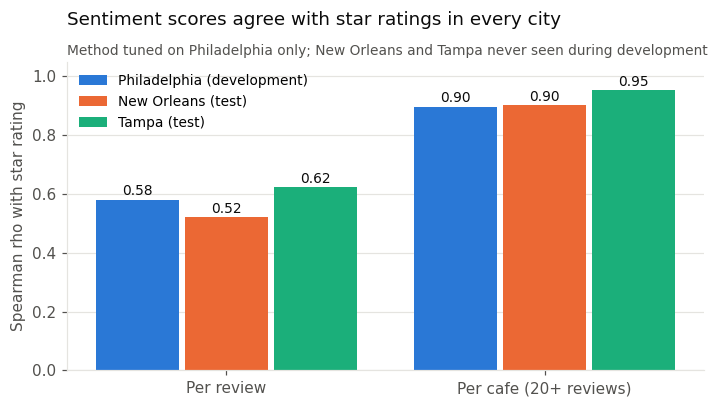

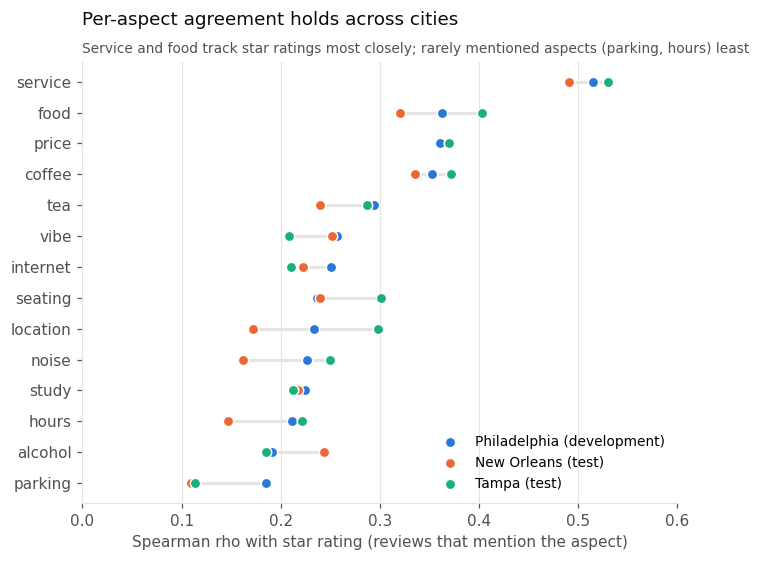

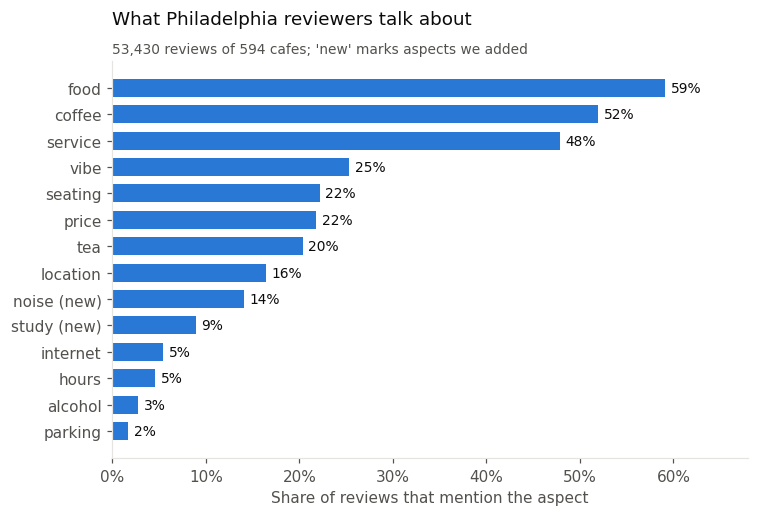

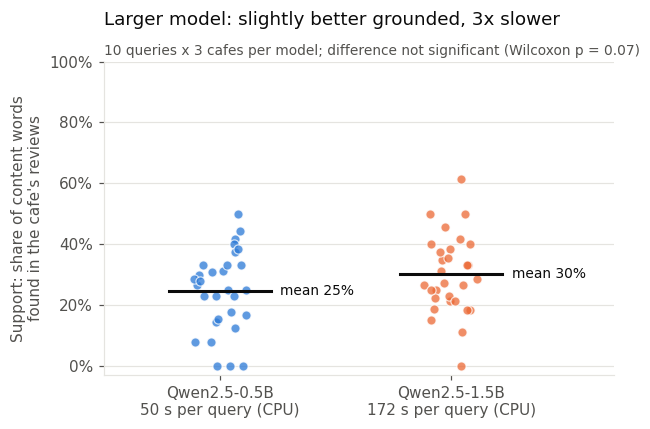

Saved figures to /content/drive/MyDrive/NLP_AT2/outputs_nb/figures


In [23]:
# Reads only files already saved to Drive (Cells 7 and 16), so it also works
# after a disconnect with just Cells 0 and 1 re-run. PNGs go to outputs_nb/figures.
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
CITY_COLORS = {"philadelphia": "#2a78d6", "new_orleans": "#eb6834", "tampa": "#1baf7a"}
CITY_LABELS = {"philadelphia": "Philadelphia (development)", "new_orleans": "New Orleans (test)",
               "tampa": "Tampa (test)"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200})


def finish(fig, ax, name, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK2)
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    plt.show()


cc = pd.read_csv(OUT / "cross_city.csv", index_col=0).drop(index="role").apply(pd.to_numeric)
cities = list(CITY_COLORS)

# 1. Validation across cities: agreement with star ratings.
fig, ax = plt.subplots(figsize=(7, 3.8))
groups = ["review-level rho", "cafe-level rho (20+ reviews)"]
w = 0.26
for i, c in enumerate(cities):
    xs = np.arange(len(groups)) + (i - 1) * (w + 0.02)
    vals = cc.loc[groups, c].values
    ax.bar(xs, vals, width=w, color=CITY_COLORS[c], label=CITY_LABELS[c])
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(len(groups)), ["Per review", "Per cafe (20+ reviews)"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Spearman rho with star rating")
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", fontsize=9)
finish(fig, ax, "fig1_cross_city_validation.png",
       "Sentiment scores agree with star ratings in every city",
       "Method tuned on Philadelphia only; New Orleans and Tampa never seen during development")

# 2. Per-aspect agreement, all three cities.
asp = [a for a in ASPECTS if f"{a} rho" in cc.index]
order = cc.loc[[f"{a} rho" for a in asp], "philadelphia"].sort_values().index
fig, ax = plt.subplots(figsize=(7, 5.2))
for y, row in enumerate(order):
    vals = cc.loc[row, cities].values
    ax.plot([vals.min(), vals.max()], [y, y], color=GRID, linewidth=2, zorder=1)
    for c in cities:
        ax.scatter(cc.loc[row, c], y, s=46, color=CITY_COLORS[c], zorder=2,
                   edgecolor="white", linewidth=1, label=CITY_LABELS[c] if y == 0 else None)
ax.set_yticks(range(len(order)), [r.replace(" rho", "") for r in order])
ax.set_xlim(0, max(0.6, cc.loc[order, cities].values.max() + 0.05))
ax.set_xlabel("Spearman rho with star rating (reviews that mention the aspect)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right", fontsize=9)
finish(fig, ax, "fig2_aspect_validation.png", "Per-aspect agreement holds across cities",
       "Service and food track star ratings most closely; rarely mentioned aspects (parking, hours) least")

# 3. How often each aspect is discussed (Philadelphia).
ra = pd.read_parquet(OUT / "philadelphia" / "review_aspects.parquet")
cov = pd.Series({a: ra[f"{a}_mentioned"].mean() for a in ASPECTS}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(cov)), cov.values, color="#2a78d6", height=0.68)
for y, v in enumerate(cov.values):
    ax.text(v + 0.006, y, f"{v:.0%}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(cov)), [f"{a} (new)" if a in ("noise", "study") else a for a in cov.index])
ax.set_xlim(0, cov.max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of reviews that mention the aspect")
finish(fig, ax, "fig3_aspect_coverage.png", "What Philadelphia reviewers talk about",
       f"{len(ra):,} reviews of {ra['shop_id'].nunique()} cafes; 'new' marks aspects we added")

# 4. Local LLM comparison, with a paired significance test.
res = pd.read_csv(OUT / "llm_eval.csv")
models = sorted(res["model"].unique())
paired = res.pivot_table(index=["query", "rank", "shop"], columns="model", values="support").dropna()
p_value = wilcoxon(paired[models[1]], paired[models[0]]).pvalue
verdict = "not significant" if p_value >= 0.05 else "significant"
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(6, 4))
labels = []
for i, (m, color) in enumerate(zip(models, ["#2a78d6", "#eb6834"])):
    s = res.loc[res["model"] == m, "support"].values
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(s)), s, s=36, color=color, alpha=0.75,
               edgecolor="white", linewidth=0.8)
    ax.plot([i - 0.22, i + 0.22], [s.mean()] * 2, color=INK, linewidth=2)
    ax.text(i + 0.26, s.mean(), f"mean {s.mean():.0%}", va="center", fontsize=9, color=INK)
    secs = res.loc[res["model"] == m, "seconds_per_query"].mean()
    labels.append(f"{m.split('/')[-1].replace('-Instruct', '')}\n{secs:.0f} s per query (CPU)")
ax.set_xticks(range(len(models)), labels)
ax.set_xlim(-0.5, len(models) - 0.3)
ax.set_ylim(-0.03, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Support: share of content words\nfound in the cafe's reviews")
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
finish(fig, ax, "fig4_llm_comparison.png", "Larger model: slightly better grounded, 3x slower",
       f"{res['query'].nunique()} queries x 3 cafes per model; difference {verdict} "
       f"(Wilcoxon p = {p_value:.2f})")
print("Saved figures to", FIG)

In [24]:
# Meaning-based retrieval using last night's embeddings. Only the query is
# embedded at search time, so this runs fine on CPU.
from sentence_transformers import SentenceTransformer


class DenseRetriever:
    name = "dense"
    def __init__(self, emb_path, model_name):
        self.E = np.load(emb_path).astype(np.float32)   # float32 for fast matrix maths
        self.model = SentenceTransformer(model_name, device="cpu")
    def similarities(self, text):
        q = self.model.encode([text], normalize_embeddings=True, convert_to_numpy=True)[0]
        return self.E @ q                                # cosine similarity (vectors normalised)


meta = json.loads((idx_dir / "dense_meta.json").read_text())
dense = DenseRetriever(idx_dir / "dense_embeddings.npy", meta["model"])
assert len(dense.E) == len(sents), "embeddings and sentence table are out of sync"
rec_dense = Recommender(sents, shops[APP_CITY], profiles[APP_CITY], dense)

# The 10 evaluation queries, plus 3 that name none of our aspects, where the
# retriever alone decides the ranking.
EVAL_QUERIES = [
    "quiet cafe for studying with good coffee and wifi", "lively place for brunch with friends",
    "cafe with board games", "cheap bubble tea", "cozy place to read a book",
    "great espresso and friendly baristas", "outdoor seating where I can work on my laptop",
    "somewhere open late to study", "vegan pastries and good coffee", "dog friendly cafe with a patio"]
NO_ASPECT_QUERIES = ["great spot for a first date", "where artists and creatives hang out",
                     "somewhere to take my parents when they visit"]

rows = []
for q in EVAL_QUERIES + NO_ASPECT_QUERIES:
    a = [r["shop"] for r in rec.recommend(q, k=5)["results"]]
    b = [r["shop"] for r in rec_dense.recommend(q, k=5)["results"]]
    rows.append({"query": q, "type": "no aspect" if q in NO_ASPECT_QUERIES else "eval",
                 "overlap@5": len(set(a) & set(b)),
                 "tfidf top 3": " | ".join(a[:3]), "dense top 3": " | ".join(b[:3])})
cmp = pd.DataFrame(rows)
cmp.to_csv(OUT / "retriever_comparison.csv", index=False)
print(cmp[["type", "overlap@5", "query"]].to_string(index=False))
print("\nMean top-5 overlap:", cmp.groupby("type")["overlap@5"].mean().round(1).to_dict())

for q in NO_ASPECT_QUERIES:
    print("\n" + "#" * 30, "TF-IDF")
    show(q, k=2)
    print("\n" + "#" * 30, "DENSE")
    show(q, k=2, recommender=rec_dense)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

     type  overlap@5                                             query
     eval          2 quiet cafe for studying with good coffee and wifi
     eval          4              lively place for brunch with friends
     eval          2                             cafe with board games
     eval          4                                  cheap bubble tea
     eval          3                         cozy place to read a book
     eval          2              great espresso and friendly baristas
     eval          2     outdoor seating where I can work on my laptop
     eval          2                      somewhere open late to study
     eval          4                    vegan pastries and good coffee
     eval          1                    dog friendly cafe with a patio
no aspect          0                       great spot for a first date
no aspect          3              where artists and creatives hang out
no aspect          1      somewhere to take my parents when they visit

Mean 

In [25]:
# Cell 21: pack the files the app needs into one zip on Drive
import zipfile

idx = OUT / "philadelphia" / "index"
app_files = {
    "sentences.parquet": idx / "sentences.parquet",
    "dense_embeddings.npy": idx / "dense_embeddings.npy",
    "dense_meta.json": idx / "dense_meta.json",
    "shops.csv": OUT / "philadelphia" / "shops.csv",
    "shop_profiles.csv": OUT / "philadelphia" / "shop_profiles.csv",
}
bundle = OUT / "brewview_app_data.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for name, path in app_files.items():
        z.write(path, arcname=name)
        print(f"added {name:<22} {path.stat().st_size / 1e6:7.1f} MB")
print(f"\nBundle: {bundle} ({bundle.stat().st_size / 1e6:.0f} MB)")

added sentences.parquet         21.4 MB
added dense_embeddings.npy     293.7 MB
added dense_meta.json            0.0 MB
added shops.csv                  0.1 MB
added shop_profiles.csv          0.7 MB

Bundle: /content/drive/MyDrive/NLP_AT2/outputs_nb/brewview_app_data.zip (290 MB)
